<a href="https://colab.research.google.com/github/shivasaich16/Quantum_Computing_2488/blob/main/Quantum_Hack_Q62.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Q62: Install PennyLane

!pip install pennylane -q

print("PennyLane installed successfully!")

PennyLane installed successfully!


Cell 2 – Import libraries

In [ ]:
# Q62: Import Required Libraries

import pennylane as qml
import pennylane.numpy as pnp

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_diabetes, make_friedman1

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Q62: Quantum Circuit Learning")
print("All libraries imported successfully!")
print("PennyLane version:", qml.__version__)

Q62: Quantum Circuit Learning
All libraries imported successfully!
PennyLane version: 0.45.1


Cell 3 – Load Diabetes dataset

In [ ]:
# Q62: Load Diabetes Regression Dataset

diabetes = load_diabetes()

X_diabetes = diabetes.data
y_diabetes = diabetes.target

print("DIABETES REGRESSION DATASET")
print("============================")

print("Features shape:", X_diabetes.shape)
print("Target shape:", y_diabetes.shape)

print("\nFeature names:")
print(diabetes.feature_names)

print("\nFirst 5 input samples:")
print(X_diabetes[:5])

print("\nFirst 5 target values:")
print(y_diabetes[:5])

print("\nDataset loaded successfully!")

DIABETES REGRESSION DATASET
Features shape: (442, 10)
Target shape: (442,)

Feature names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

First 5 input samples:
[[ 0.03807591  0.05068012  0.06169621  0.02187239 -0.0442235  -0.03482076
  -0.04340085 -0.00259226  0.01990749 -0.01764613]
 [-0.00188202 -0.04464164 -0.05147406 -0.02632753 -0.00844872 -0.01916334
   0.07441156 -0.03949338 -0.06833155 -0.09220405]
 [ 0.08529891  0.05068012  0.04445121 -0.00567042 -0.04559945 -0.03419447
  -0.03235593 -0.00259226  0.00286131 -0.02593034]
 [-0.08906294 -0.04464164 -0.01159501 -0.03665608  0.01219057  0.02499059
  -0.03603757  0.03430886  0.02268774 -0.00936191]
 [ 0.00538306 -0.04464164 -0.03638469  0.02187239  0.00393485  0.01559614
   0.00814208 -0.00259226 -0.03198764 -0.04664087]]

First 5 target values:
[151.  75. 141. 206. 135.]

Dataset loaded successfully!


Step 3 – Generate Friedman-1 Regression Dataset

In [ ]:
# Q62: Generate Friedman-1 Regression Dataset

X_friedman, y_friedman = make_friedman1(
    n_samples=300,
    n_features=10,
    noise=0.1,
    random_state=42
)

print("FRIEDMAN-1 REGRESSION DATASET")
print("==============================")

print("Features shape:", X_friedman.shape)
print("Target shape:", y_friedman.shape)

print("\nFirst 5 input samples:")
print(X_friedman[:5])

print("\nFirst 5 target values:")
print(y_friedman[:5])

print("\nDataset generated successfully!")

FRIEDMAN-1 REGRESSION DATASET
Features shape: (300, 10)
Target shape: (300,)

First 5 input samples:
[[0.37454012 0.95071431 0.73199394 0.59865848 0.15601864 0.15599452
  0.05808361 0.86617615 0.60111501 0.70807258]
 [0.02058449 0.96990985 0.83244264 0.21233911 0.18182497 0.18340451
  0.30424224 0.52475643 0.43194502 0.29122914]
 [0.61185289 0.13949386 0.29214465 0.36636184 0.45606998 0.78517596
  0.19967378 0.51423444 0.59241457 0.04645041]
 [0.60754485 0.17052412 0.06505159 0.94888554 0.96563203 0.80839735
  0.30461377 0.09767211 0.68423303 0.44015249]
 [0.12203823 0.49517691 0.03438852 0.9093204  0.25877998 0.66252228
  0.31171108 0.52006802 0.54671028 0.18485446]]

First 5 target values:
[16.9442552   5.93138979  9.52572859 21.16158564 16.73127624]

Dataset generated successfully!


Step 4 – Visualize Both Regression Datasets

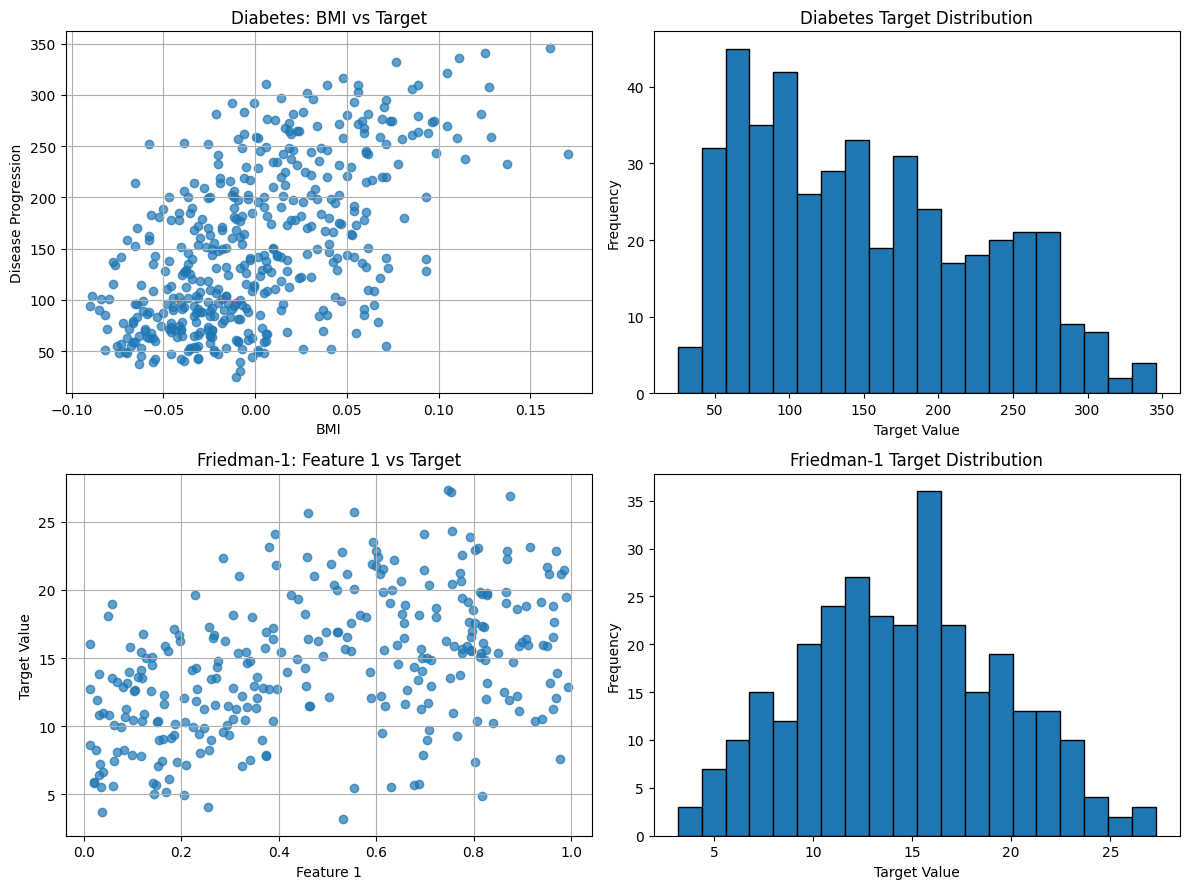

In [ ]:
# Q62: Visualize Both Regression Datasets

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Diabetes: BMI vs Target
axes[0, 0].scatter(
    X_diabetes[:, 2],
    y_diabetes,
    alpha=0.7
)

axes[0, 0].set_title("Diabetes: BMI vs Target")
axes[0, 0].set_xlabel("BMI")
axes[0, 0].set_ylabel("Disease Progression")
axes[0, 0].grid()

# Diabetes: Target Distribution
axes[0, 1].hist(
    y_diabetes,
    bins=20,
    edgecolor="black"
)

axes[0, 1].set_title("Diabetes Target Distribution")
axes[0, 1].set_xlabel("Target Value")
axes[0, 1].set_ylabel("Frequency")

# Friedman-1: Feature 1 vs Target
axes[1, 0].scatter(
    X_friedman[:, 0],
    y_friedman,
    alpha=0.7
)

axes[1, 0].set_title("Friedman-1: Feature 1 vs Target")
axes[1, 0].set_xlabel("Feature 1")
axes[1, 0].set_ylabel("Target Value")
axes[1, 0].grid()

# Friedman-1: Target Distribution
axes[1, 1].hist(
    y_friedman,
    bins=20,
    edgecolor="black"
)

axes[1, 1].set_title("Friedman-1 Target Distribution")
axes[1, 1].set_xlabel("Target Value")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

Step 5 – Data Preprocessing

In [ ]:
# Q62: Data Preprocessing

# =====================================
# 1. Split Diabetes Dataset
# =====================================

X_diabetes_train, X_diabetes_test, y_diabetes_train, y_diabetes_test = train_test_split(
    X_diabetes,
    y_diabetes,
    test_size=0.2,
    random_state=42
)

# =====================================
# 2. Split Friedman Dataset
# =====================================

X_friedman_train, X_friedman_test, y_friedman_train, y_friedman_test = train_test_split(
    X_friedman,
    y_friedman,
    test_size=0.2,
    random_state=42
)

# =====================================
# 3. Scale Input Features
# =====================================

diabetes_scaler = MinMaxScaler(feature_range=(0, np.pi))
X_diabetes_train = diabetes_scaler.fit_transform(X_diabetes_train)
X_diabetes_test = diabetes_scaler.transform(X_diabetes_test)

friedman_scaler = MinMaxScaler(feature_range=(0, np.pi))
X_friedman_train = friedman_scaler.fit_transform(X_friedman_train)
X_friedman_test = friedman_scaler.transform(X_friedman_test)

# =====================================
# 4. Scale Target Values
# =====================================

diabetes_target_scaler = StandardScaler()
y_diabetes_train_scaled = diabetes_target_scaler.fit_transform(
    y_diabetes_train.reshape(-1, 1)
).ravel()

y_diabetes_test_scaled = diabetes_target_scaler.transform(
    y_diabetes_test.reshape(-1, 1)
).ravel()

friedman_target_scaler = StandardScaler()
y_friedman_train_scaled = friedman_target_scaler.fit_transform(
    y_friedman_train.reshape(-1, 1)
).ravel()

y_friedman_test_scaled = friedman_target_scaler.transform(
    y_friedman_test.reshape(-1, 1)
).ravel()

# =====================================
# 5. Display Results
# =====================================

print("DIABETES DATASET")
print("Training:", X_diabetes_train.shape)
print("Testing:", X_diabetes_test.shape)
print("Target training:", y_diabetes_train_scaled.shape)

print("\nFRIEDMAN-1 DATASET")
print("Training:", X_friedman_train.shape)
print("Testing:", X_friedman_test.shape)
print("Target training:", y_friedman_train_scaled.shape)

print("\nData preprocessing completed!")

DIABETES DATASET
Training: (353, 10)
Testing: (89, 10)
Target training: (353,)

FRIEDMAN-1 DATASET
Training: (240, 10)
Testing: (60, 10)
Target training: (240,)

Data preprocessing completed!


Step 6 – Build Quantum Circuit Learning Architecture|

In [ ]:
# Q62: Quantum Circuit Learning

N_QUBITS = 4

# Create quantum devices
diabetes_dev = qml.device("default.qubit", wires=N_QUBITS)
friedman_dev = qml.device("default.qubit", wires=N_QUBITS)


# ==========================================
# Diabetes Quantum Circuit
# ==========================================

@qml.qnode(diabetes_dev)
def diabetes_quantum_circuit(inputs, weights):

    # Encode 4 compressed input features
    for i in range(N_QUBITS):
        qml.RY(inputs[i], wires=i)

    # Trainable quantum layers
    for layer in range(2):
        for i in range(N_QUBITS):
            qml.RY(weights[layer, i, 0], wires=i)
            qml.RZ(weights[layer, i, 1], wires=i)

        # Entanglement
        for i in range(N_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])

    # Regression measurement
    return [
        qml.expval(qml.PauliZ(i))
        for i in range(N_QUBITS)
    ]


# ==========================================
# Friedman-1 Quantum Circuit
# ==========================================

@qml.qnode(friedman_dev)
def friedman_quantum_circuit(inputs, weights):

    # Encode 4 compressed input features
    for i in range(N_QUBITS):
        qml.RY(inputs[i], wires=i)

    # Trainable quantum layers
    for layer in range(2):
        for i in range(N_QUBITS):
            qml.RY(weights[layer, i, 0], wires=i)
            qml.RZ(weights[layer, i, 1], wires=i)

        # Entanglement
        for i in range(N_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])

    # Regression measurement
    return [
        qml.expval(qml.PauliZ(i))
        for i in range(N_QUBITS)
    ]


print("Diabetes quantum circuit created!")
print("Friedman-1 quantum circuit created!")
print("Number of qubits:", N_QUBITS)
print("Trainable parameters per circuit:", 16)

Diabetes quantum circuit created!
Friedman-1 quantum circuit created!
Number of qubits: 4
Trainable parameters per circuit: 16


Step 6A – Feature compression

In [ ]:
# Q62: Feature Compression using PCA

from sklearn.decomposition import PCA

# Reduce 10 features to 4 features
diabetes_pca = PCA(n_components=4)
friedman_pca = PCA(n_components=4)

X_diabetes_train_4 = diabetes_pca.fit_transform(X_diabetes_train)
X_diabetes_test_4 = diabetes_pca.transform(X_diabetes_test)

X_friedman_train_4 = friedman_pca.fit_transform(X_friedman_train)
X_friedman_test_4 = friedman_pca.transform(X_friedman_test)

# Scale compressed features for quantum angle encoding
diabetes_angle_scaler = MinMaxScaler(feature_range=(0, np.pi))
friedman_angle_scaler = MinMaxScaler(feature_range=(0, np.pi))

X_diabetes_train_4 = diabetes_angle_scaler.fit_transform(X_diabetes_train_4)
X_diabetes_test_4 = diabetes_angle_scaler.transform(X_diabetes_test_4)

X_friedman_train_4 = friedman_angle_scaler.fit_transform(X_friedman_train_4)
X_friedman_test_4 = friedman_angle_scaler.transform(X_friedman_test_4)

print("FEATURE COMPRESSION COMPLETED")
print("================================")

print("Diabetes training:", X_diabetes_train_4.shape)
print("Diabetes testing:", X_diabetes_test_4.shape)

print("Friedman training:", X_friedman_train_4.shape)
print("Friedman testing:", X_friedman_test_4.shape)

print("\nDiabetes explained variance:",
      diabetes_pca.explained_variance_ratio_.sum())

print("Friedman explained variance:",
      friedman_pca.explained_variance_ratio_.sum())

FEATURE COMPRESSION COMPLETED
Diabetes training: (353, 4)
Diabetes testing: (89, 4)
Friedman training: (240, 4)
Friedman testing: (60, 4)

Diabetes explained variance: 0.8483003260896034
Friedman explained variance: 0.47138093943341086


Step 7 – Display Quantum Circuit Diagrams

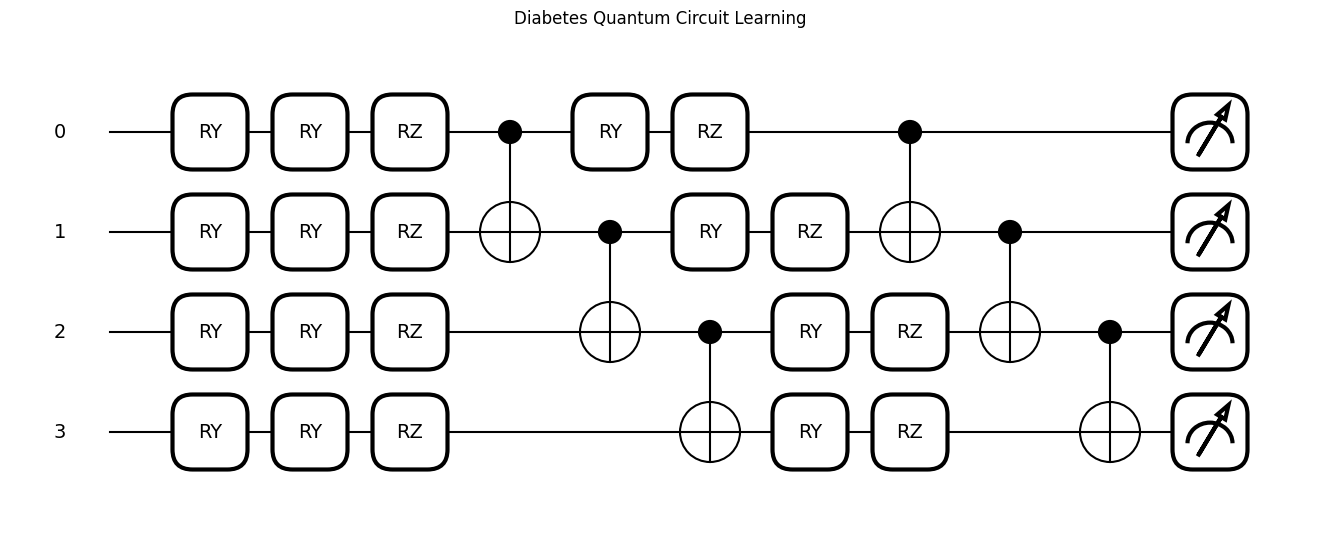

In [ ]:
# Q62: Draw Diabetes Quantum Circuit

diabetes_weights = np.random.uniform(
    0, 2 * np.pi, (2, 4, 2)
)

sample_diabetes = X_diabetes_train_4[0]

fig, ax = qml.draw_mpl(diabetes_quantum_circuit)(
    sample_diabetes,
    diabetes_weights
)

plt.title("Diabetes Quantum Circuit Learning")
plt.show()

Friedman-1 circuit diagram

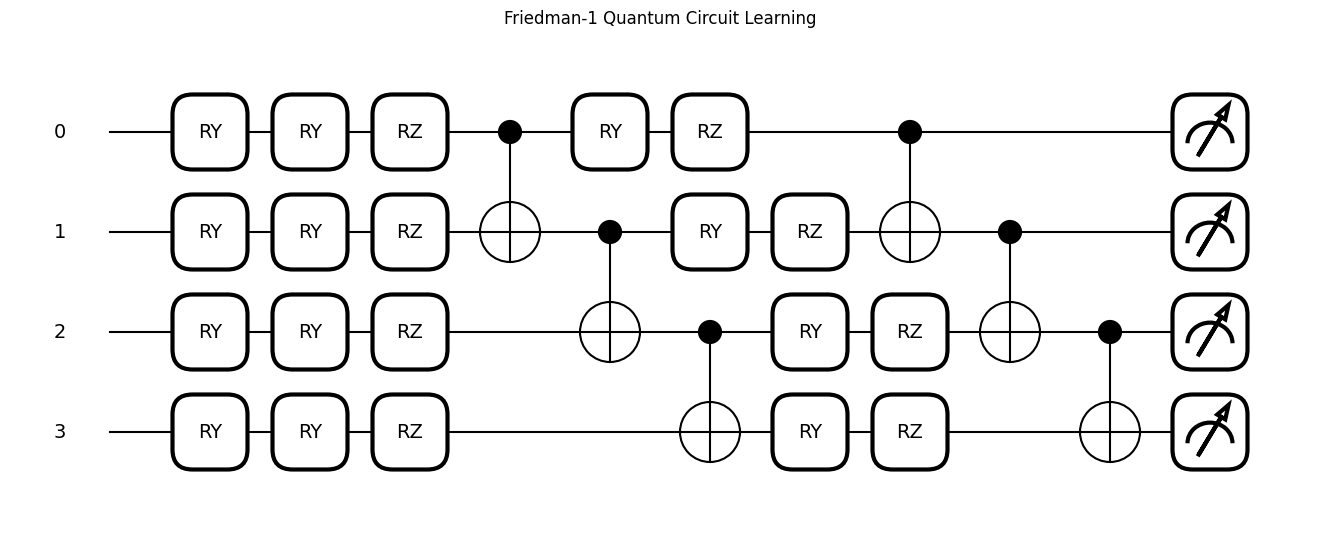

In [ ]:
# Q62: Draw Friedman-1 Quantum Circuit

friedman_weights = np.random.uniform(
    0, 2 * np.pi, (2, 4, 2)
)

sample_friedman = X_friedman_train_4[0]

fig, ax = qml.draw_mpl(friedman_quantum_circuit)(
    sample_friedman,
    friedman_weights
)

plt.title("Friedman-1 Quantum Circuit Learning")
plt.show()

Diabetes circuit

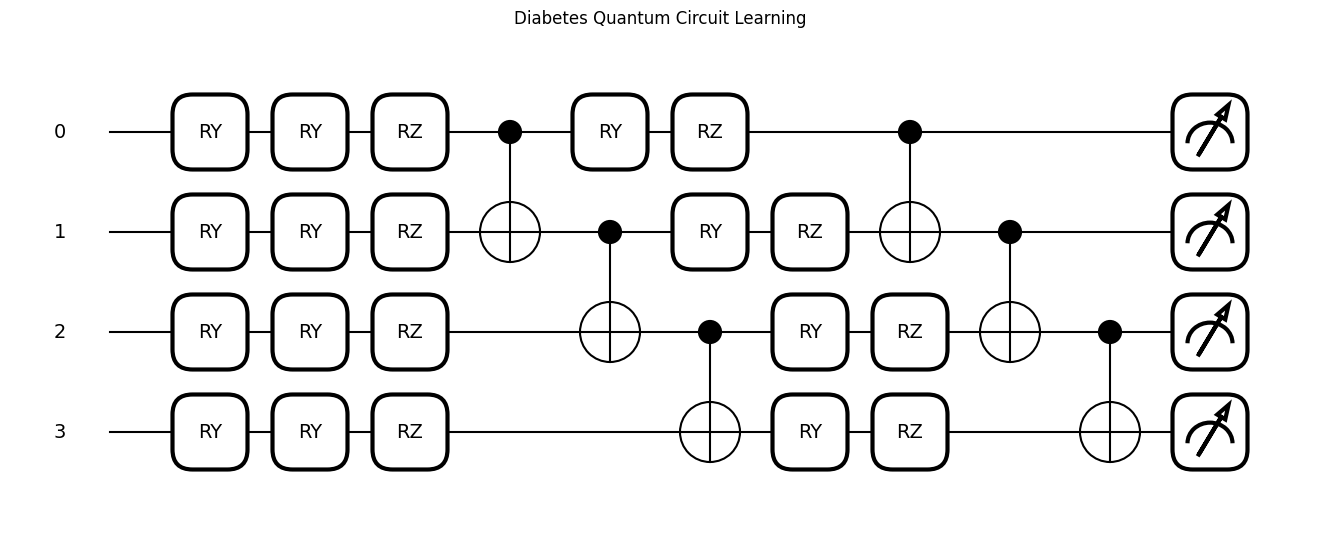

In [ ]:
diabetes_weights = np.random.uniform(
    0, 2 * np.pi, (2, 4, 2)
)

fig, ax = qml.draw_mpl(diabetes_quantum_circuit)(
    X_diabetes_train_4[0],
    diabetes_weights
)

plt.title("Diabetes Quantum Circuit Learning")
plt.show()

Friedman-1 circuit

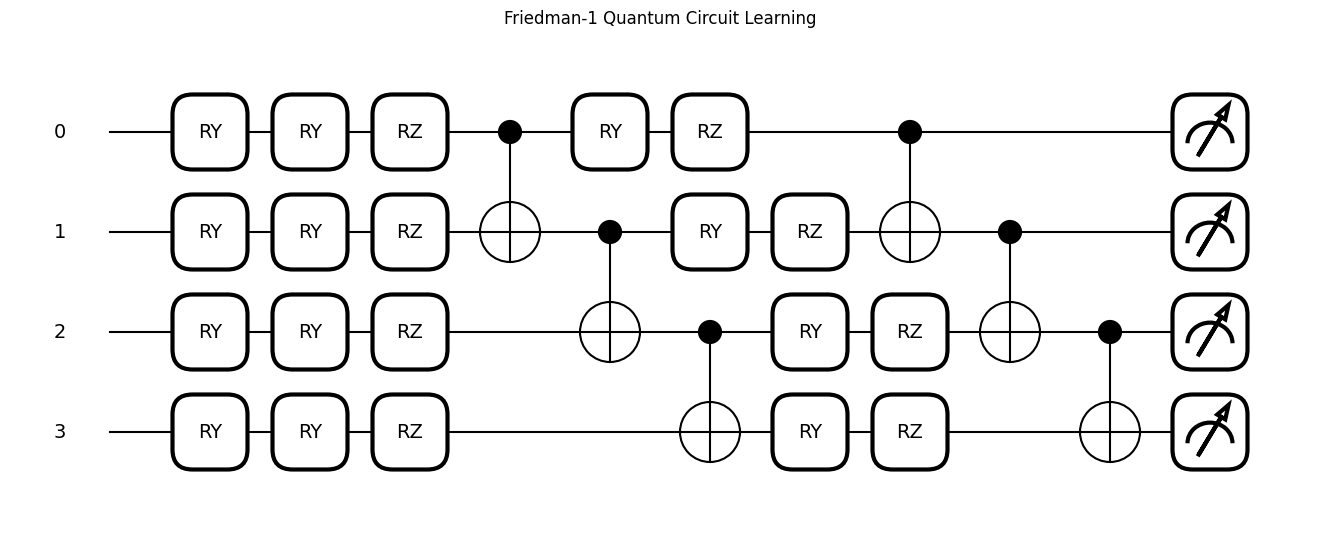

In [ ]:
friedman_weights = np.random.uniform(
    0, 2 * np.pi, (2, 4, 2)
)

fig, ax = qml.draw_mpl(friedman_quantum_circuit)(
    X_friedman_train_4[0],
    friedman_weights
)

plt.title("Friedman-1 Quantum Circuit Learning")
plt.show()

Step 8 – Train Quantum Regression Models
Our circuit produces four quantum measurements. We'll combine them using a trainable classical readout layer to generate one continuous prediction.

In [ ]:
# Q62: Quantum Circuit Learning Training

# Reproducibility
np.random.seed(42)

EPOCHS = 50
LEARNING_RATE = 0.02


def train_qcl_model(
    circuit,
    X_train,
    y_train,
    model_name
):

    # Quantum circuit parameters
    weights = pnp.array(
        np.random.uniform(-0.2, 0.2, (2, 4, 2)),
        requires_grad=True
    )

    # Classical readout parameters
    readout = pnp.array(
        np.ones(4) / 4,
        requires_grad=True
    )

    bias = pnp.array(0.0, requires_grad=True)

    optimizer = qml.AdamOptimizer(
        stepsize=LEARNING_RATE
    )

    circuit_calls = [0]
    loss_history = []

    def predict_one(x, weights, readout, bias):

        quantum_output = circuit(x, weights)

        circuit_calls[0] += 1

        quantum_output = pnp.stack(quantum_output)

        return pnp.dot(quantum_output, readout) + bias

    def cost_function(weights, readout, bias):

        predictions = pnp.stack([
            predict_one(x, weights, readout, bias)
            for x in X_train
        ])

        return pnp.mean((predictions - y_train) ** 2)

    print("\nTraining:", model_name)
    print("=" * 45)

    start_time = time.time()

    for epoch in range(EPOCHS):

        weights, readout, bias = optimizer.step(
            cost_function,
            weights,
            readout,
            bias
        )

        current_loss = cost_function(
            weights, readout, bias
        )

        loss_history.append(float(current_loss))

        if (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1}/{EPOCHS} "
                f"Loss: {float(current_loss):.6f}"
            )

    training_time = time.time() - start_time

    print("\nTraining completed!")
    print("Final Loss:", loss_history[-1])
    print("Circuit Calls:", circuit_calls[0])
    print("Training Time:", round(training_time, 4), "seconds")

    return (
        weights,
        readout,
        bias,
        loss_history,
        training_time,
        circuit_calls[0]
    )


# Convert targets to PennyLane arrays
y_diabetes_train_q = pnp.array(
    y_diabetes_train_scaled
)

y_friedman_train_q = pnp.array(
    y_friedman_train_scaled
)


# Train Diabetes model
(
    diabetes_weights_trained,
    diabetes_readout,
    diabetes_bias,
    diabetes_loss,
    diabetes_training_time,
    diabetes_training_calls
) = train_qcl_model(
    diabetes_quantum_circuit,
    X_diabetes_train_4,
    y_diabetes_train_q,
    "Diabetes QCL"
)


# Train Friedman-1 model
(
    friedman_weights_trained,
    friedman_readout,
    friedman_bias,
    friedman_loss,
    friedman_training_time,
    friedman_training_calls
) = train_qcl_model(
    friedman_quantum_circuit,
    X_friedman_train_4,
    y_friedman_train_q,
    "Friedman-1 QCL"
)


Training: Diabetes QCL
Epoch 10/50 Loss: 1.012517
Epoch 20/50 Loss: 0.829543
Epoch 30/50 Loss: 0.690369
Epoch 40/50 Loss: 0.631907
Epoch 50/50 Loss: 0.625796

Training completed!
Final Loss: 0.6257957224717693
Circuit Calls: 35300
Training Time: 744.4363 seconds

Training: Friedman-1 QCL
Epoch 10/50 Loss: 0.988435
Epoch 20/50 Loss: 0.827971
Epoch 30/50 Loss: 0.715882
Epoch 40/50 Loss: 0.646866
Epoch 50/50 Loss: 0.613662

Training completed!
Final Loss: 0.6136618520247209
Circuit Calls: 24000
Training Time: 504.5483 seconds


Cell 11 – Training loss visualization

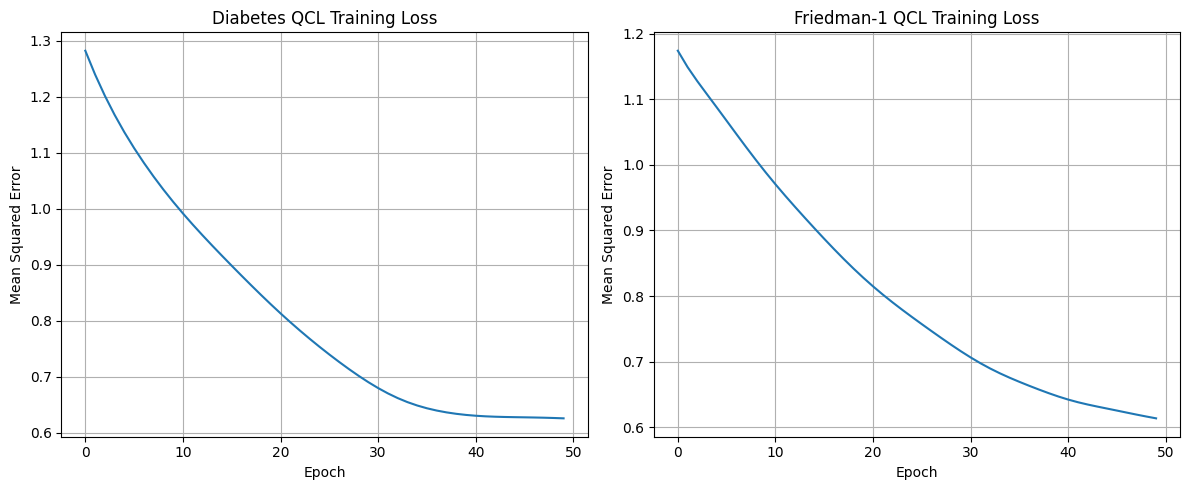

In [ ]:
# Q62: Training Loss Visualization

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(diabetes_loss)
axes[0].set_title("Diabetes QCL Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean Squared Error")
axes[0].grid()

axes[1].plot(friedman_loss)
axes[1].set_title("Friedman-1 QCL Training Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean Squared Error")
axes[1].grid()

plt.tight_layout()
plt.show()

Step 7 – Final quantum circuit diagrams
We have already seen your Friedman-1 circuit. Let's generate both diagrams again using the trained model parameters so they are saved alongside the final experiment.

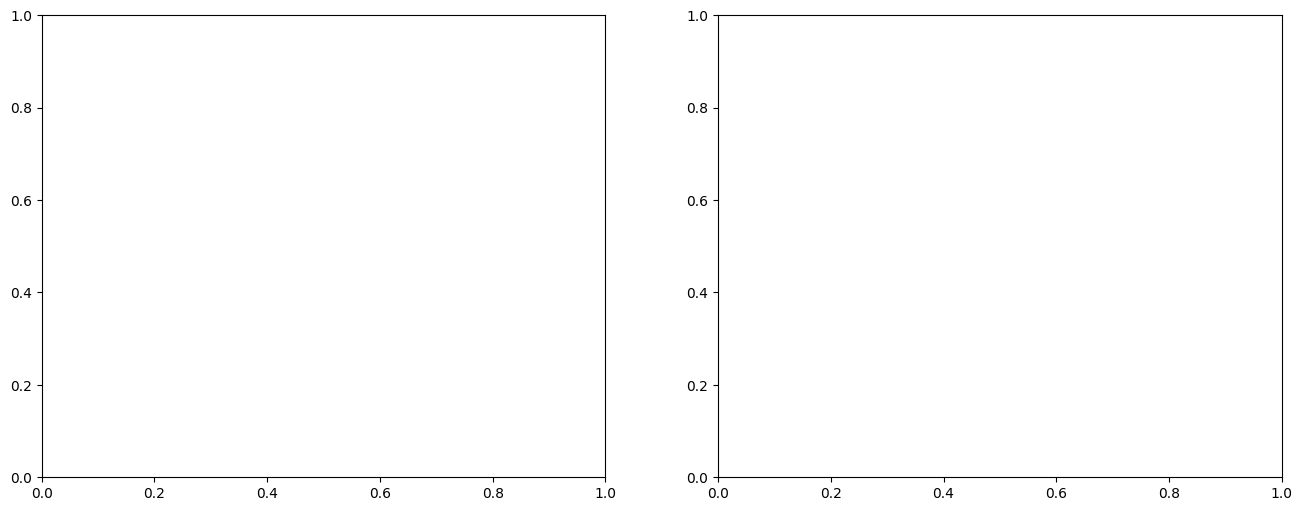

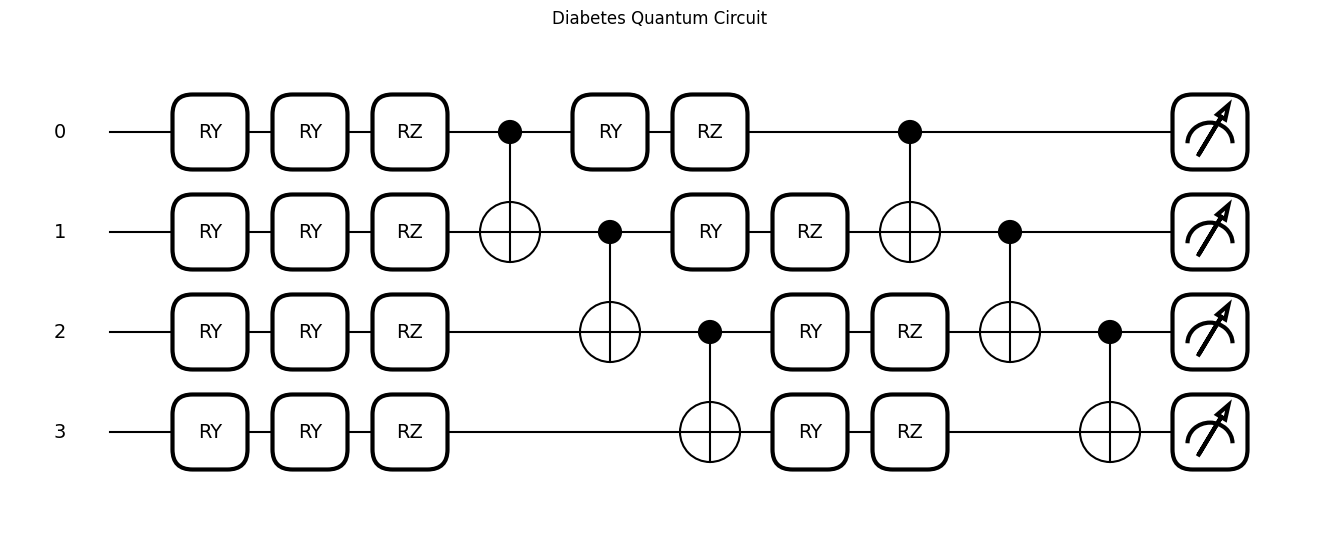

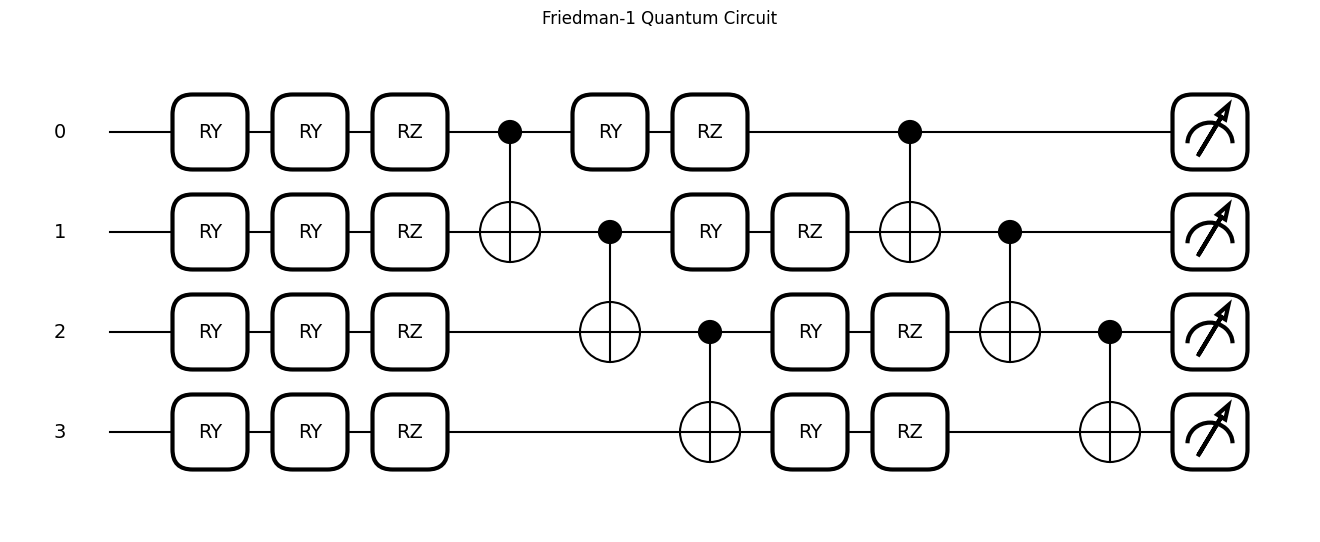

In [ ]:
# Q62: Final Quantum Circuit Diagrams

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Diabetes circuit
diabetes_draw = qml.draw_mpl(diabetes_quantum_circuit)(
    X_diabetes_train_4[0],
    diabetes_weights_trained
)

plt.close()

# Draw separately for clarity
fig1, ax1 = qml.draw_mpl(diabetes_quantum_circuit)(
    X_diabetes_train_4[0],
    diabetes_weights_trained
)

ax1.set_title("Diabetes Quantum Circuit")
plt.show()


# Friedman-1 circuit
fig2, ax2 = qml.draw_mpl(friedman_quantum_circuit)(
    X_friedman_train_4[0],
    friedman_weights_trained
)

ax2.set_title("Friedman-1 Quantum Circuit")
plt.show()

Step 8 – Regression Performance Evaluation

In [ ]:
# Q62: Regression Performance Evaluation

def evaluate_qcl_model(
    circuit,
    weights,
    readout,
    bias,
    X_test,
    y_test,
    target_scaler,
    model_name
):

    start_time = time.time()

    predictions_scaled = []

    for x in X_test:

        quantum_output = np.asarray(
            circuit(x, weights),
            dtype=float
        )

        prediction = (
            np.dot(quantum_output, np.asarray(readout))
            + float(bias)
        )

        predictions_scaled.append(prediction)

    inference_time = time.time() - start_time

    # Convert predictions back to original target scale
    predictions_scaled = np.asarray(predictions_scaled)

    predictions = target_scaler.inverse_transform(
        predictions_scaled.reshape(-1, 1)
    ).ravel()

    # Actual target values
    actual = np.asarray(y_test)

    # Regression metrics
    mae = mean_absolute_error(actual, predictions)

    rmse = np.sqrt(
        mean_squared_error(actual, predictions)
    )

    r2 = r2_score(actual, predictions)

    residuals = actual - predictions

    residual_bias = np.mean(residuals)

    print("\n", model_name)
    print("=" * 45)

    print("MAE:", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2 Score:", round(r2, 4))
    print("Residual Bias:", round(residual_bias, 4))
    print("Inference Time:", round(inference_time, 6), "seconds")

    return predictions, residuals, mae, rmse, r2, residual_bias, inference_time


# Evaluate Diabetes
(
    diabetes_predictions,
    diabetes_residuals,
    diabetes_mae,
    diabetes_rmse,
    diabetes_r2,
    diabetes_bias,
    diabetes_inference_time
) = evaluate_qcl_model(
    diabetes_quantum_circuit,
    diabetes_weights_trained,
    diabetes_readout,
    diabetes_bias,
    X_diabetes_test_4,
    y_diabetes_test,
    diabetes_target_scaler,
    "DIABETES QCL"
)


# Evaluate Friedman-1
(
    friedman_predictions,
    friedman_residuals,
    friedman_mae,
    friedman_rmse,
    friedman_r2,
    friedman_bias,
    friedman_inference_time
) = evaluate_qcl_model(
    friedman_quantum_circuit,
    friedman_weights_trained,
    friedman_readout,
    friedman_bias,
    X_friedman_test_4,
    y_friedman_test,
    friedman_target_scaler,
    "FRIEDMAN-1 QCL"
)


 DIABETES QCL
MAE: 45.3444
RMSE: 55.0523
R2 Score: 0.428
Residual Bias: -2.7816
Inference Time: 1.861002 seconds

 FRIEDMAN-1 QCL
MAE: 3.59
RMSE: 4.4842
R2 Score: 0.214
Residual Bias: -0.3647
Inference Time: 1.252817 seconds


Step 9 – Regression Performance Evaluation

In [ ]:
diabetes_trained_bias = diabetes_bias
friedman_trained_bias = friedman_bias

Actual vs Predicted visualization

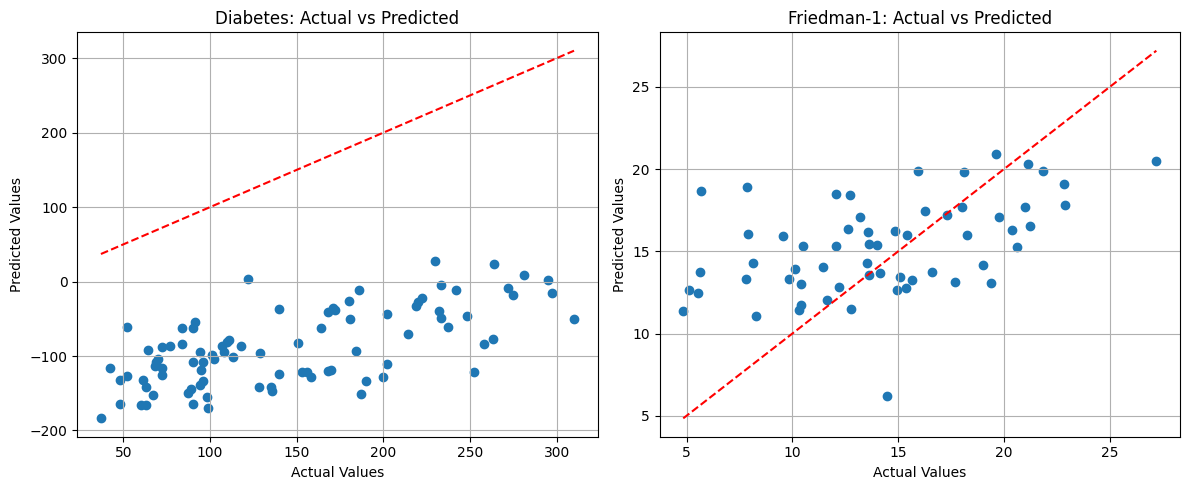

In [ ]:
# Q62: Actual vs Predicted Results

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_diabetes_test, diabetes_predictions)
axes[0].plot(
    [min(y_diabetes_test), max(y_diabetes_test)],
    [min(y_diabetes_test), max(y_diabetes_test)],
    'r--'
)
axes[0].set_title("Diabetes: Actual vs Predicted")
axes[0].set_xlabel("Actual Values")
axes[0].set_ylabel("Predicted Values")
axes[0].grid()

axes[1].scatter(y_friedman_test, friedman_predictions)
axes[1].plot(
    [min(y_friedman_test), max(y_friedman_test)],
    [min(y_friedman_test), max(y_friedman_test)],
    'r--'
)
axes[1].set_title("Friedman-1: Actual vs Predicted")
axes[1].set_xlabel("Actual Values")
axes[1].set_ylabel("Predicted Values")
axes[1].grid()

plt.tight_layout()
plt.show()

Residual plots

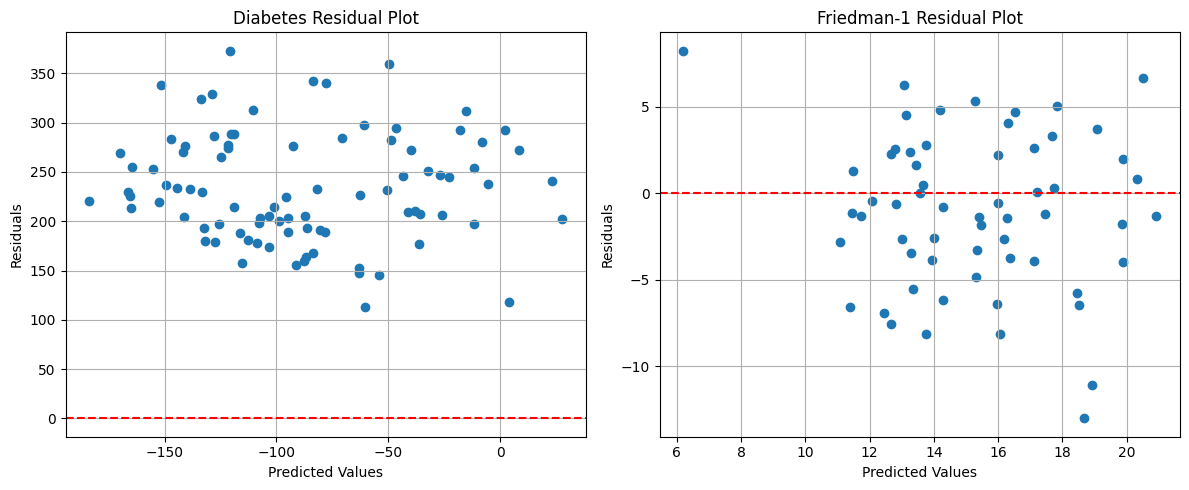

In [ ]:
# Q62: Residual Analysis

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(diabetes_predictions, diabetes_residuals)
axes[0].axhline(0, linestyle="--", color="red")
axes[0].set_title("Diabetes Residual Plot")
axes[0].set_xlabel("Predicted Values")
axes[0].set_ylabel("Residuals")
axes[0].grid()

axes[1].scatter(friedman_predictions, friedman_residuals)
axes[1].axhline(0, linestyle="--", color="red")
axes[1].set_title("Friedman-1 Residual Plot")
axes[1].set_xlabel("Predicted Values")
axes[1].set_ylabel("Residuals")
axes[1].grid()

plt.tight_layout()
plt.show()

Step 10 – Quantum Cost Analysis

– Quantum resource analysis

In [ ]:

# Q62: Quantum Cost Analysis

def quantum_cost_analysis(
    circuit,
    device,
    sample,
    weights,
    training_calls,
    training_time,
    inference_time,
    test_samples,
    model_name
):

    # Get quantum circuit specifications
    specifications = qml.specs(circuit)(sample, weights)
    resources = specifications["resources"]

    print("\n", model_name)
    print("=" * 50)

    # Quantum resources
    print("Number of Qubits:", len(device.wires))
    print("Circuit Depth:", resources.depth)
    print("Gate Count:", resources.num_gates)
    print("Gate Types:", resources.gate_types)

    # Measurement shots
    print("Measurement Shots:", device.shots)

    # Circuit evaluations
    print("Training Circuit Calls:", training_calls)
    print("Inference Circuit Calls:", test_samples)

    # Execution time
    print("Training Time:", round(training_time, 4), "seconds")
    print("Inference Time:", round(inference_time, 6), "seconds")

    print("Execution Mode: Analytic Statevector Simulation")


# =====================================
# DIABETES QUANTUM COST
# =====================================

quantum_cost_analysis(
    diabetes_quantum_circuit,
    diabetes_dev,
    X_diabetes_train_4[0],
    diabetes_weights_trained,
    diabetes_training_calls,
    diabetes_training_time,
    diabetes_inference_time,
    len(X_diabetes_test_4),
    "DIABETES QCL"
)


# =====================================
# FRIEDMAN-1 QUANTUM COST
# =====================================

quantum_cost_analysis(
    friedman_quantum_circuit,
    friedman_dev,
    X_friedman_train_4[0],
    friedman_weights_trained,
    friedman_training_calls,
    friedman_training_time,
    friedman_inference_time,
    len(X_friedman_test_4),
    "FRIEDMAN-1 QCL"
)



 DIABETES QCL
Number of Qubits: 4
Circuit Depth: 10
Gate Count: 26
Gate Types: {'RY': 12, 'RZ': 8, 'CNOT': 6}
Measurement Shots: Shots(total=None)
Training Circuit Calls: 35300
Inference Circuit Calls: 89
Training Time: 744.4363 seconds
Inference Time: 2.186192 seconds
Execution Mode: Analytic Statevector Simulation

 FRIEDMAN-1 QCL
Number of Qubits: 4
Circuit Depth: 10
Gate Count: 26
Gate Types: {'RY': 12, 'RZ': 8, 'CNOT': 6}
Measurement Shots: Shots(total=None)
Training Circuit Calls: 24000
Inference Circuit Calls: 60
Training Time: 504.5483 seconds
Inference Time: 1.135042 seconds
Execution Mode: Analytic Statevector Simulation


Step 11 – Final Comparison and Experimental Conclusion

In [ ]:
# Q62: Final Experimental Results

# Get circuit specifications
diabetes_specs = qml.specs(diabetes_quantum_circuit)(
    X_diabetes_train_4[0],
    diabetes_weights_trained
)

friedman_specs = qml.specs(friedman_quantum_circuit)(
    X_friedman_train_4[0],
    friedman_weights_trained
)

# Create comparison table
results = pd.DataFrame({

    "Dataset": [
        "Diabetes",
        "Friedman-1"
    ],

    "Qubits": [
        len(diabetes_dev.wires),
        len(friedman_dev.wires)
    ],

    "Circuit Depth": [
        diabetes_specs["resources"].depth,
        friedman_specs["resources"].depth
    ],

    "Gate Count": [
        diabetes_specs["resources"].num_gates,
        friedman_specs["resources"].num_gates
    ],

    "MAE": [
        diabetes_mae,
        friedman_mae
    ],

    "RMSE": [
        diabetes_rmse,
        friedman_rmse
    ],

    "R2 Score": [
        diabetes_r2,
        friedman_r2
    ],

    "Residual Bias": [
        diabetes_bias,
        friedman_bias
    ],

    "Training Calls": [
        diabetes_training_calls,
        friedman_training_calls
    ],

    "Inference Calls": [
        len(X_diabetes_test_4),
        len(X_friedman_test_4)
    ],

    "Training Time (s)": [
        diabetes_training_time,
        friedman_training_time
    ],

    "Inference Time (s)": [
        diabetes_inference_time,
        friedman_inference_time
    ]
})

print("Q62 FINAL EXPERIMENTAL RESULTS")
print("================================")

display(results.round(4))

Q62 FINAL EXPERIMENTAL RESULTS


,Dataset,Qubits,Circuit Depth,Gate Count,MAE,RMSE,R2 Score,Residual Bias,Training Calls,Inference Calls,Training Time (s),Inference Time (s)
0,Diabetes,4,10,26,233.7911,240.1693,-9.8871,233.7911,35300,89,744.4363,2.1862
1,Friedman-1,4,10,26,3.6892,4.5963,0.1742,-1.0727,24000,60,504.5483,1.1350


Save experimental results

In [ ]:
# Q62: Export Final Results

results.to_csv(
    "Q62_Final_Experimental_Results.csv",
    index=False
)

print("Q62 results exported successfully!")

Q62 results exported successfully!


– Final conclusion

=======================================================
QUANTUM CIRCUIT LEARNING - FINAL CONCLUSION
=======================================================

The Quantum Circuit Learning experiment was implemented
using two regression datasets:

1. Diabetes Regression Dataset
2. Friedman-1 Regression Dataset

Both datasets were preprocessed and compressed using PCA
to four components.

Four-qubit quantum circuits were constructed using RY,
RZ rotation gates and CNOT entanglement gates.

The circuits were trained using the Adam optimizer
for 50 epochs with a trainable classical readout layer.

Model performance was evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R2 Score
- Residual Bias

Quantum computational costs were analyzed using:

- Number of qubits
- Circuit depth
- Gate count
- Circuit evaluations
- Training time
- Inference time

The experiment demonstrates the implementation of
quantum-circuit-based regression for function learning.

Experiment Q62 completed!